# Fast Food Marketing Campaign A\B Test

## Introduction

### Overview

This dataset includes A/B test results of a new fast food item sales to examine which marketing campaign was the most successful. The new item was introduced at different locations in several randomly selected markets.

Dataset includes:
- MarketID - a number for a randomly selected market (10 in total)
- MarketSize - size of market area by sales (small, medium, large)
- LocationID - store location unique ID (137 in total)
- AgeOfStore - age of store in years
- Promotion - promotion tested (3 in total)
- week - week when the promotions were run (4 in total)
- SalesInThousands - sales amount for a specific LocationID, Promotion, and week


### Goal of the analysis

The goal of this analysis is to decide which marketing campaign was the most successful and lead to the most sales of the new item.

Questions to analyse:
1. Is there a statistically significant difference in mean sales across three promotions?
2. How can the promotions can be ranked from the most to the least successful?

### Target metric

- SalesInThousands: sales in the first 4 weeks of introducing the new item (by a specific promotion in a specific location) in thousands. The more sales there were, the more successful the campaign was in promoting the new product.

### Calculations

#### 1. Data overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from fast_food_functions import histogram, histogram_compare_groups, histogram_with_ci

In [2]:
df_food = pd.read_csv("./WA_Marketing-Campaign.csv")
df_food.head()

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands
0,1,Medium,1,4,3,1,33.73
1,1,Medium,1,4,3,2,35.67
2,1,Medium,1,4,3,3,29.03
3,1,Medium,1,4,3,4,39.25
4,1,Medium,2,5,2,1,27.81


In [3]:
df_food['sales'] = df_food['SalesInThousands'] * 1000

In [4]:
df_food.head()

,MarketID,MarketSize,LocationID,AgeOfStore,Promotion,week,SalesInThousands,sales
0,1,Medium,1,4,3,1,33.73,33730.0
1,1,Medium,1,4,3,2,35.67,35670.0
2,1,Medium,1,4,3,3,29.03,29030.0
3,1,Medium,1,4,3,4,39.25,39250.0
4,1,Medium,2,5,2,1,27.81,27810.0


In [5]:
print(f"Dataframe shape: {df_food.shape}")
print(f"\nMissing values:\n{df_food.isna().sum()}")
print(f"\nDuplicated entries: {df_food.duplicated().sum()}")

Dataframe shape: (548, 8)

Missing values:
MarketID            0
MarketSize          0
LocationID          0
AgeOfStore          0
Promotion           0
week                0
SalesInThousands    0
sales               0
dtype: int64

Duplicated entries: 0


In [6]:
print(f"Number of markets analysed: {df_food['MarketID'].nunique()}")
market_sizes = df_food['MarketSize'].unique()
print("Market types:", ", ".join(market_sizes))
print(f"Number of locations analysed: {df_food['LocationID'].nunique()}")
promotion_numbers = df_food['Promotion'].unique()
print("Promotions:", ", ".join([str(p) for p in promotion_numbers]))
print(f"Weeks of analysis: {df_food['week'].max()}")

Number of markets analysed: 10
Market types: Medium, Small, Large
Number of locations analysed: 137
Promotions: 3, 2, 1
Weeks of analysis: 4


In [7]:
age_stats = (
    r"$\bf{Store\ age\ statistics}$" + "\n"
    f"Count: {len(df_food['AgeOfStore'])}\n"
    f"Median: {df_food['AgeOfStore'].median():.2f}\n"
    f"Mean: {df_food['AgeOfStore'].mean():.2f}\n"
    f"Std: {df_food['AgeOfStore'].std():.2f}\n"
    f"Min: {df_food['AgeOfStore'].min():.0f}\n"
    f"Max: {df_food['AgeOfStore'].max():.0f}"
)

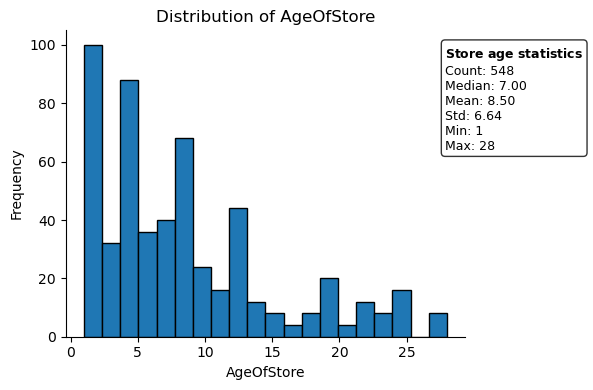

In [8]:
histogram(df=df_food, col='AgeOfStore', stats_text=age_stats)

In [9]:
sales_stats = (
    r"$\bf{Sales\ statistics}$" + "\n"
    f"Count: {len(df_food['sales'])}\n"
    f"Median: {df_food['sales'].median():.2f}\n"
    f"Mean: {df_food['sales'].mean():.2f}\n"
    f"Std: {df_food['sales'].std():.2f}\n"
    f"Min: {df_food['sales'].min():.0f}\n"
    f"Max: {df_food['sales'].max():.0f}"
)

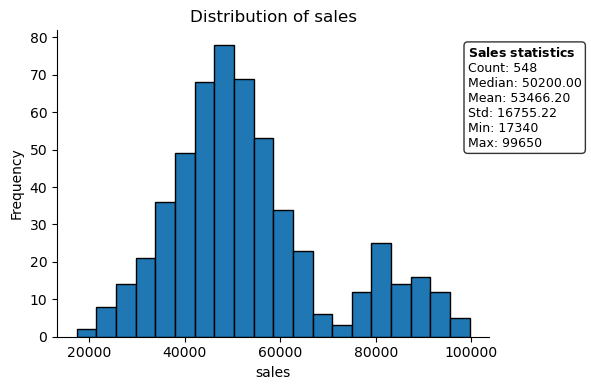

In [10]:
histogram(df=df_food, col='sales', stats_text=sales_stats)

In [11]:
promotion_sales_text = {}

for i in range (1,4):
    data = df_food[df_food['Promotion'] == i]['sales']
    promotion_sales_text[i] = {"Count": len(data),
                     'Median': data.median(),
                     'Mean': round(data.mean(),2),
                     'Std': round(data.std(), 2),
                     'Min': round(data.min()),
                     'Max': round(data.max())
                     }

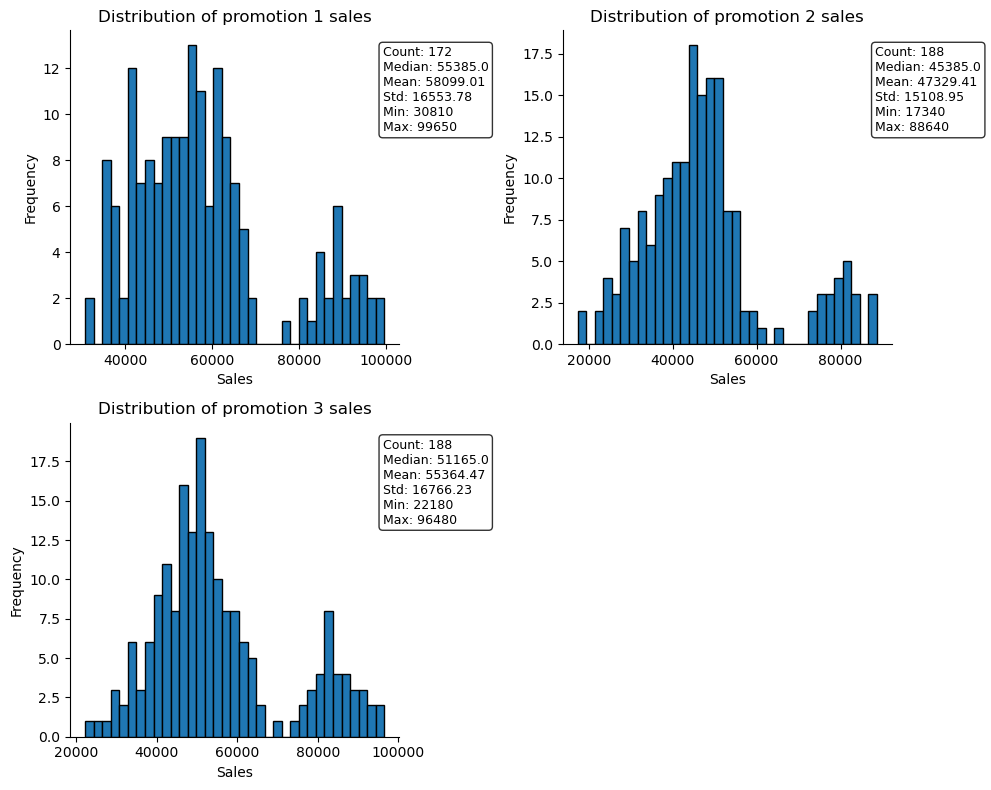

In [12]:
histogram_compare_groups(df=df_food, group='Promotion', metric='sales', figsize=(10,8), bins=35, stats_text = promotion_sales_text)

#### 2. Statistical tests

##### First hypothesis of the analysis (promotion effectiveness)

- H0: there is no statistically significant difference in mean sales across three promotions
- H1: there is a statistically significant difference in mean sales across three promotions

Variance homogeneity can be tested using Levene test:
- H₀: variances are homogeneous.
- H₁: variances are not homogeneous.

In [13]:
promotion_sales_text = {}

for i in range (1,4):
    data = df_food[df_food['Promotion'] == i]['sales']
    promotion_sales_text[i] = {"Count": len(data),
                     'Median': data.median(),
                     'Mean': round(data.mean(),2),
                     'Std': round(data.std(), 2),
                     'Min': round(data.min()),
                     'Max': round(data.max())
                     }

In [14]:
df_food_grouped_sales = df_food.groupby('LocationID').agg({
    'sales': 'sum',
    'Promotion': 'first'
})

In [15]:
promotions = {}

for i in range(1,4):
    promotions[i] = df_food_grouped_sales[df_food_grouped_sales['Promotion'] == i]['sales']

In [16]:
statistic, p_value = stats.levene(*promotions.values())
statistic, p_value

(0.46816084440167766, 0.6271730417231256)

Since the p value is > 0.05, variances are homogenous.

In [17]:
scipy_ci = {}

for i in range(1,4):
    data = promotions[i]
    mean = data.mean()
    std = data.std() / np.sqrt(len(data))
    scipy_ci[i] = stats.t.interval(confidence=0.95, df=len(data)-1, loc=mean, scale=std)

In [18]:
bootstrap_ci = {}
for i in range(1,4):
    data = promotions[i]
    result = stats.bootstrap(data = (data, ), statistic = np.mean, confidence_level = 0.95, method = 'percentile', random_state=51)
    bootstrap_ci[i] = (result.confidence_interval.low, result.confidence_interval.high)

In [19]:
means = [promotions[i].mean() for i in range(1, 4)]
scipy_ci_list = [scipy_ci[i] for i in range(1, 4)]
bootstrap_ci_list = [bootstrap_ci[i] for i in range(1, 4)]

In [20]:
scipy_lower_errors = []
scipy_upper_errors = []

for mean, ci in zip(means, scipy_ci_list):
    lower_error = mean - ci[0]
    scipy_lower_errors.append(lower_error)
    upper_error = ci[1] - mean
    scipy_upper_errors.append(upper_error)

In [21]:
bootstrap_lower_errors = []
bootstrap_upper_errors = []

for mean, ci in zip(means, bootstrap_ci_list):
    lower_error = mean - ci[0]
    bootstrap_lower_errors.append(lower_error)
    upper_error = ci[1] - mean
    bootstrap_upper_errors.append(upper_error)

In [22]:
statistic, p_value = stats.kruskal(*promotions.values())
n = sum(len(data) for data in promotions.values())
epsilon_squared = statistic / (n - 1)

In [23]:
kruskal_wallis_test_text = (
    r"$\bf{Kruskal\ Wallis\ test}$" + "\n" +
    f"H-statistic: {statistic:.4f}\n" +
    f"p-value: {p_value:.4f}\n" +
    f"Epsilon-squared (effect size): {epsilon_squared:.3f}\n" +
    f"Result: {'Significant' if p_value < 0.05 else 'Not significant'}\n" +
    f"Effect size: {'Negligible' if epsilon_squared < 0.01 else 'Small' if epsilon_squared < 0.08 else 'Medium' if epsilon_squared < 0.26 else 'Large'}"
)

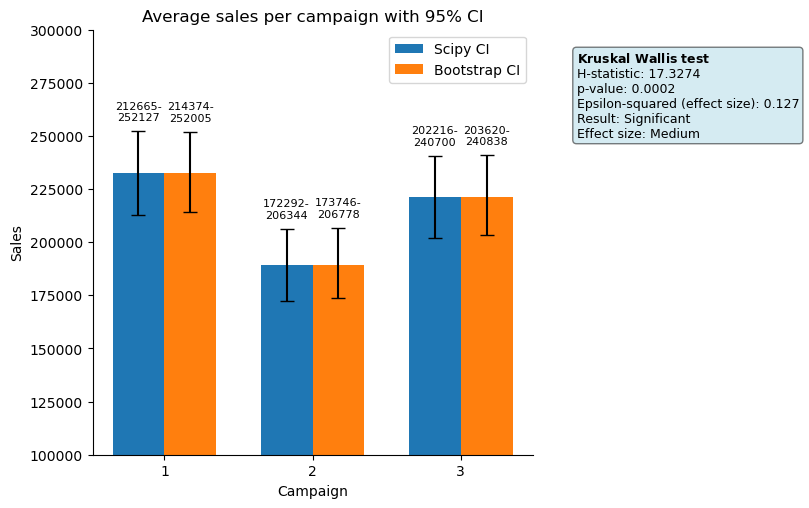

In [24]:
histogram_with_ci(means, 
                  scipy_lower_errors, 
                  scipy_upper_errors, 
                  bootstrap_lower_errors, 
                  bootstrap_upper_errors, 
                  scipy_ci_list,
                  bootstrap_ci_list,
                  title='Average sales per campaign with 95% CI',
                  ylabel='Sales', 
                  xlabel='Campaign', 
                  labels=[1,2,3], 
                  stats_text=kruskal_wallis_test_text)

We see statistically significant difference between the campaigns (p < 0.05), with medium effect size (0.127).

##### Second hypothesis of the analysis (post-hoc analysis - the most successfull promotion)
- H0: there is no difference in mean sales between any pair of promotions
- H1: at least one pair of promotions has significantly different mean sales

Using a Bonferroni correction because of the multiple testing (p value is 0.05 / 3 = 0.017)

In [25]:
post_hoc_test_text = (
    r"$\bf{Post-hoc\ test}$" + "\n" +
    f"Campaign 1 vs 2: {'Significant' if stats.mannwhitneyu(promotions[1], promotions[2])[1] < 0.017 else 'Not significant'}\n" +
    f"Campaign 1 vs 3: {'Significant' if stats.mannwhitneyu(promotions[1], promotions[3])[1] < 0.017 else 'Not significant'}\n" +
    f"Campaign 2 vs 3: {'Significant' if stats.mannwhitneyu(promotions[3], promotions[2])[1] < 0.017 else 'Not significant'}"
)

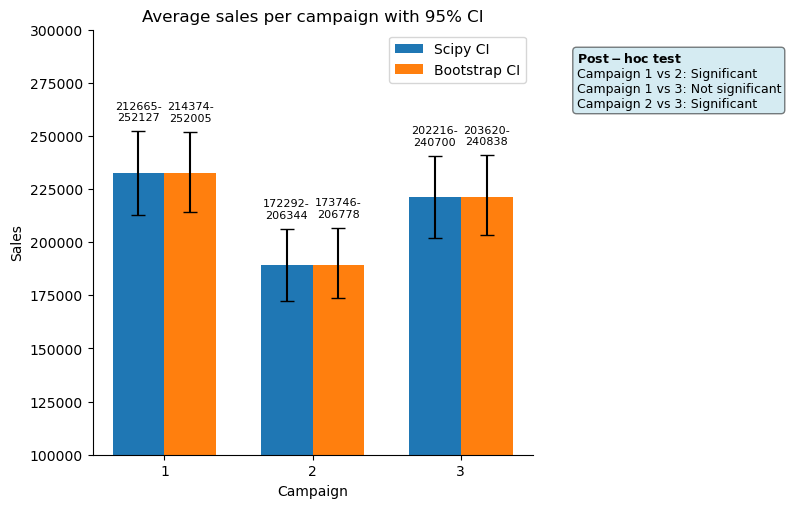

In [26]:
histogram_with_ci(means, 
                  scipy_lower_errors, 
                  scipy_upper_errors, 
                  bootstrap_lower_errors, 
                  bootstrap_upper_errors, 
                  scipy_ci_list,
                  bootstrap_ci_list,
                  title='Average sales per campaign with 95% CI',
                  ylabel='Sales', 
                  xlabel='Campaign', 
                  labels=[1,2,3], 
                  stats_text=post_hoc_test_text)

- Looking at the means, the promotion 1 is the best perfoming. Promotion 2 is the worst performing.
- There is significant differences between promotion 2 and the rest.

### Decision

Promotion 1 and 3 are statistically similar and the best performing - if we have to choose one, it's better to choose the cheaper one, since the results would be similar.

### Conclusions